# Running time until convergence

The running time until all parameters stay above an ESS of 200 (ignoring the tree topology). Runs that have not converged yet are extrapolated from the ESS per minute of their slowest parameter.

In [693]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.ess import compute_ess

In [694]:
# the run outputs live in the tests directory at the repository root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tests" / "hcv_emat.xml").exists())
TESTS_PATH = ROOT / "tests"

METHOD = "emat_mut"
TARGET_ESS = 200
BURNIN_FRACTION = 0.1
NUM_POINTS = 200

experiments = ["hcv", "zika", "sars", "ebola", "sars5000", "sars10000"]

# the wall-clock seconds per million MCMC samples of each run, which convert samples into running time
seconds_per_million_samples = {
    # "hcv": 12,
    # "zika": 19,
    # "sars": 56,
    # "ebola": 2 * 60 + 8,
    "sars5000": 5*60 + 37,
    # "sars10000": 10*60 + 59,
}

In [695]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#bbbbbb",
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "grid.color": "#e8e8e8",
        "figure.dpi": 120,
    },
)

# each experiment keeps the same color in all plots
experiment_colors = dict(zip(experiments, sns.color_palette("deep")))

In [696]:
def get_seconds_per_sample(experiment: str, log_path: Path, last_sample: int) -> float:
    """Returns the wall-clock seconds per MCMC sample, estimated from the file timestamps if no timing is known."""
    if experiment in seconds_per_million_samples:
        return seconds_per_million_samples[experiment] / 1e6

    # the log file is created at the start of the run and last modified when the last sample was logged
    stat = log_path.stat()
    elapsed_seconds = stat.st_mtime - stat.st_birthtime
    print(f"{experiment}: no timing known, estimated {elapsed_seconds / last_sample * 1e6:.0f}s per million samples from the file timestamps")
    return elapsed_seconds / last_sample


def get_num_sequences(experiment: str) -> int:
    """Returns the number of sequences, read from the header of the tree file of the run."""
    tree_path = next(TESTS_PATH.glob(f"{experiment}_{METHOD}-*.trees"))
    with open(tree_path) as file:
        for line in file:
            match = re.search(r"ntax\s*=\s*(\d+)", line, re.IGNORECASE)
            if match:
                return int(match.group(1))
    raise ValueError(f"no ntax found in {tree_path}")


logs = {}
num_sequences = {}

for experiment in experiments:
    log_paths = sorted(TESTS_PATH.glob(f"{experiment}_{METHOD}.log")) + sorted(TESTS_PATH.glob(f"{experiment}_{METHOD}-*.log"))
    if not log_paths:
        print(f"{experiment}: no log found")
        continue

    # a run that is still in progress may have a partially written last line
    log_df = pd.read_csv(log_paths[0], comment="#", delimiter="\t").dropna()

    seconds_per_sample = get_seconds_per_sample(experiment, log_paths[0], log_df["Sample"].iloc[-1])
    log_df["minutes"] = log_df["Sample"] * seconds_per_sample / 60

    logs[experiment] = log_df
    num_sequences[experiment] = get_num_sequences(experiment)

experiments = [experiment for experiment in experiments if experiment in logs]

hcv: no timing known, estimated 12s per million samples from the file timestamps
zika: no timing known, estimated 20s per million samples from the file timestamps
sars: no timing known, estimated 61s per million samples from the file timestamps
ebola: no log found
sars10000: no timing known, estimated 695s per million samples from the file timestamps


In [697]:
def get_ess_trajectory(log_df: pd.DataFrame) -> pd.DataFrame:
    """Computes the ESS of each parameter at evenly spaced points in time, as if the run were stopped there."""
    # constant columns are left out, as their ESS is undefined
    columns = [column for column in log_df.columns if column not in ["Sample", "minutes"] and log_df[column].std() > 0]
    values = log_df[columns].to_numpy(dtype=float)
    minutes = log_df["minutes"].to_numpy()

    # at least 20 states are needed for a meaningful ESS estimate
    end_indices = np.unique(np.linspace(20, len(log_df), NUM_POINTS).astype(int))

    rows = []
    for end in end_indices:
        start = int(end * BURNIN_FRACTION)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ess = [compute_ess(values[start:end, i]) for i in range(len(columns))]
        rows.append({"minutes": minutes[end - 1], **dict(zip(columns, ess))})

    return pd.DataFrame(rows).set_index("minutes")


ess_trajectories = {experiment: get_ess_trajectory(logs[experiment]) for experiment in experiments}

In [698]:
convergence_rows = []

for experiment, trajectory in ess_trajectories.items():
    end_minutes = trajectory.index[-1]

    for column in trajectory.columns:
        below_target = (trajectory[column] < TARGET_ESS).to_numpy()
        final_ess = trajectory[column].iloc[-1]

        if not below_target.any():
            minutes, projected = trajectory.index[0], False
        elif not below_target[-1]:
            # the first point after the last drop below the target
            minutes, projected = trajectory.index[len(below_target) - np.argmax(below_target[::-1])], False
        else:
            minutes, projected = TARGET_ESS / (final_ess / end_minutes), True

        convergence_rows.append({
            "experiment": experiment,
            "parameter": column,
            "minutes": minutes,
            "projected": projected,
            "ess_per_minute": final_ess / end_minutes,
        })

convergence_df = pd.DataFrame(convergence_rows)

# a run converges once its slowest-mixing parameter stays above the target ESS
summary_df = (
    convergence_df.sort_values("minutes")
    .groupby("experiment")
    .last()
    .rename(columns={"parameter": "slowest parameter"})
    .reindex(experiments)
    .reset_index()
)
summary_df["num_sequences"] = summary_df["experiment"].map(num_sequences)
summary_df["status"] = np.where(summary_df["projected"], "projected", "observed")

summary_df[["experiment", "num_sequences", "minutes", "status", "slowest parameter"]]

,experiment,num_sequences,minutes,status,slowest parameter
0,hcv,63,3.007185,observed,freqParameter.2
1,zika,174,13.360604,observed,Tree.height
2,sars,757,14.946709,observed,freqParameter.1
3,sars5000,5000,144.848217,observed,prior
4,sars10000,10000,458.636390,observed,ePopSize


## Running time until convergence

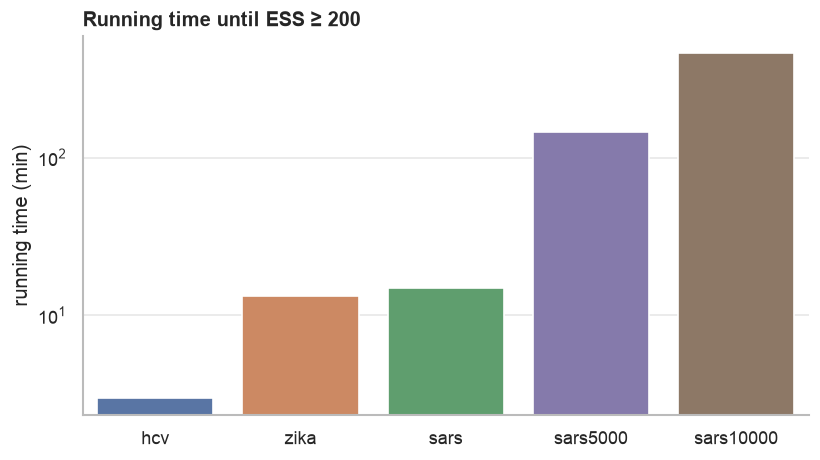

In [699]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(summary_df, x="experiment", y="minutes", hue="experiment", palette=experiment_colors, ax=ax)

# runs that have not converged yet are hatched
for bar, projected in zip(ax.patches, summary_df["projected"]):
    if projected:
        bar.set_alpha(0.5)
        bar.set_hatch("//")

ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("running time (min)")
ax.set_title("Running time until ESS ≥ 200")

fig.tight_layout()
plt.show()

/var/folders/gf/xs1vj06903d3n69s2lv68f6h0000gq/T/ipykernel_2297/1937157078.py:27: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(-0.03 * summary_df["num_sequences"].max(), summary_df["num_sequences"].max() * 1.25)


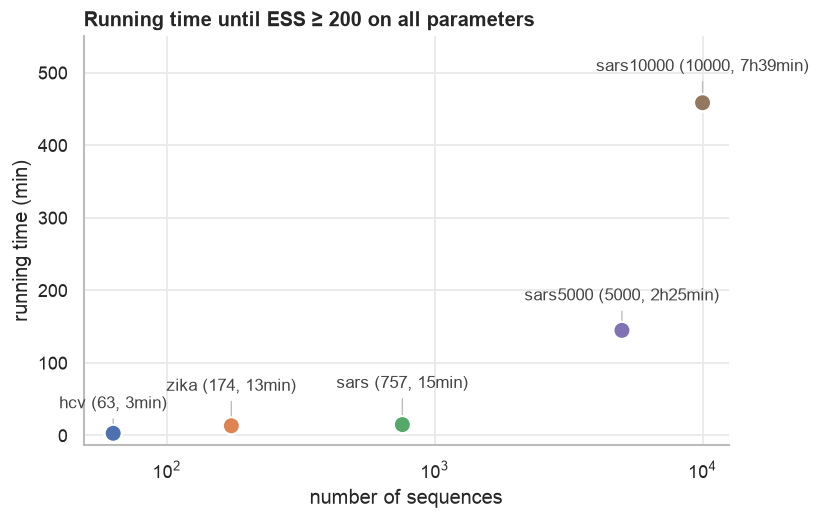

In [700]:
fig, ax = plt.subplots(figsize=(7, 4.5))

sns.scatterplot(
    summary_df, x="num_sequences", y="minutes", hue="experiment", palette=experiment_colors,
    style="status", markers={"observed": "o", "projected": "X"}, s=110, edgecolor="white", linewidth=1.5, legend=False, ax=ax,
)

def format_minutes(minutes: float) -> str:
    minutes = max(0, round(minutes))

    if minutes < 60:
        return f"{minutes}min"

    return f"{minutes // 60}h{minutes % 60}min"

# labels of neighboring points alternate in height, so that close points stay readable
np.random.seed(1)
for i, (_, row) in enumerate(summary_df.sort_values("num_sequences").iterrows()):
    label = f"{row["experiment"]} ({row["num_sequences"]}, {format_minutes(row["minutes"])})"
    ax.annotate(
        label, (row["num_sequences"], row["minutes"]), xytext=(0, np.random.randint(10, 40)), textcoords="offset points",
        ha="center", fontsize=10, color="#444444", arrowprops={"arrowstyle": "-", "color": "#bbbbbb", "linewidth": 0.8, "shrinkB": 6},
    )

# the axes start slightly below zero, so that points close to zero are not cut off
ax.set_xscale("log")
ax.set_xlim(-0.03 * summary_df["num_sequences"].max(), summary_df["num_sequences"].max() * 1.25)
ax.set_ylim(-0.03 * summary_df["minutes"].max(), summary_df["minutes"].max() * 1.2)
ax.set_xlabel("number of sequences")
ax.set_ylabel("running time (min)")
ax.set_title("Running time until ESS ≥ 200 on all parameters")

fig.tight_layout()
fig.savefig("convergence_time.png", dpi=200, bbox_inches="tight")
plt.show()

## ESS of the slowest parameter over running time

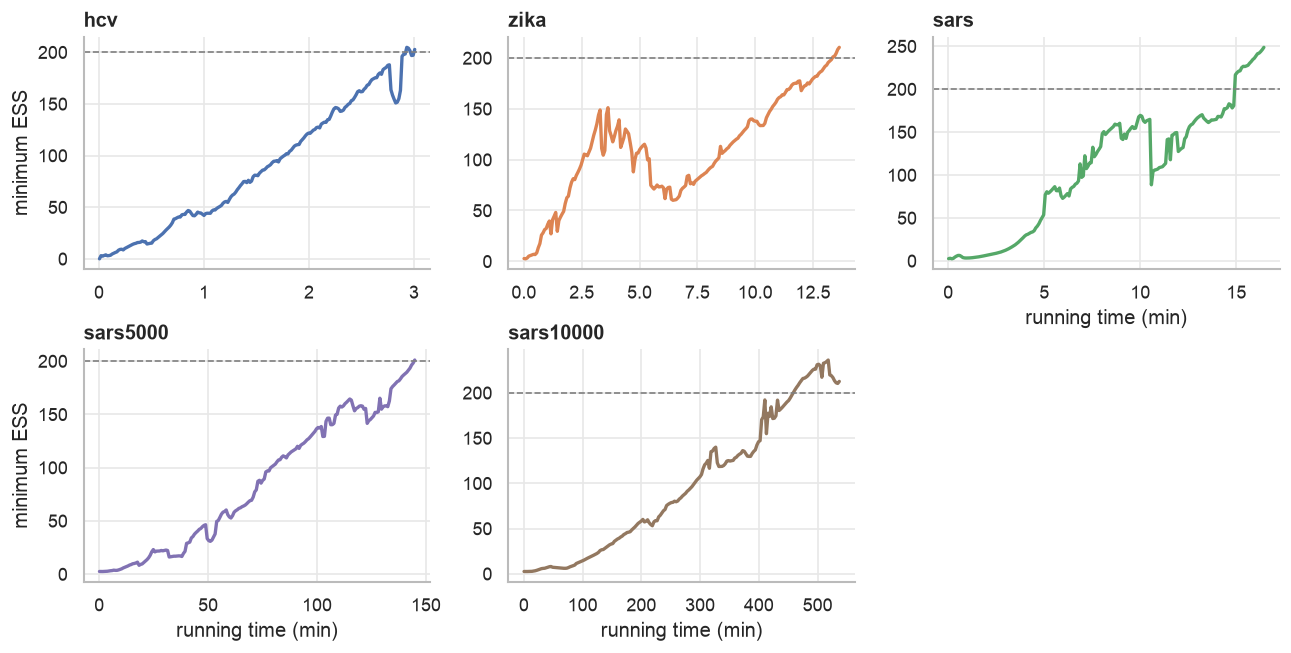

In [701]:
min_ess_df = pd.concat([
    pd.DataFrame({"minutes": trajectory.index, "ess": trajectory.min(axis=1).to_numpy(), "experiment": experiment})
    for experiment, trajectory in ess_trajectories.items()
])

grid = sns.relplot(
    min_ess_df, x="minutes", y="ess", col="experiment", hue="experiment", palette=experiment_colors,
    kind="line", linewidth=2, col_wrap=3, height=2.8, aspect=1.3, facet_kws={"sharex": False, "sharey": False}, legend=False,
)
for ax in grid.axes.flat:
    ax.axhline(TARGET_ESS, color="gray", linestyle="--", linewidth=1)
grid.set_titles("{col_name}", fontweight="bold")
grid.set_axis_labels("running time (min)", "minimum ESS")

plt.show()

## Time until ESS ≥ 200 per parameter

Relative to the slowest parameter of each run.

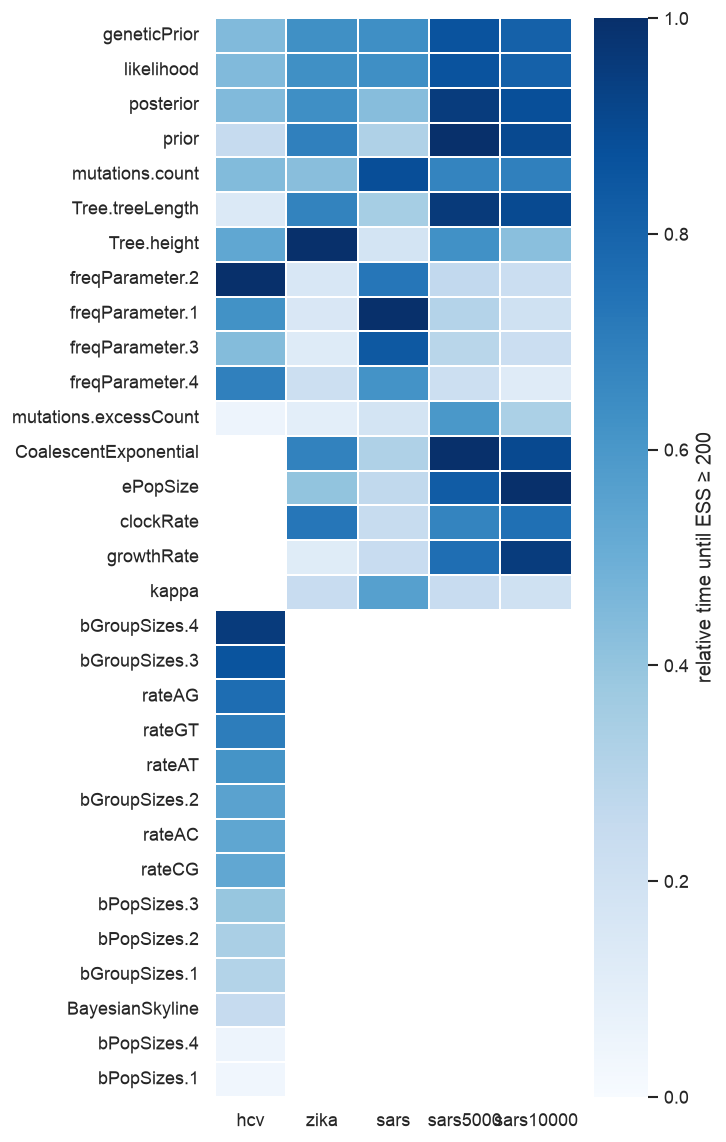

In [702]:
relative_df = convergence_df.pivot(index="parameter", columns="experiment", values="minutes")[experiments]
relative_df = relative_df / relative_df.max()

# parameters shared by more experiments are listed first
order_df = pd.DataFrame({"count": relative_df.notna().sum(axis=1), "mean": relative_df.mean(axis=1)})
relative_df = relative_df.loc[order_df.sort_values(["count", "mean"], ascending=False).index]

fig, ax = plt.subplots(figsize=(6, 0.28 * len(relative_df) + 1))

sns.heatmap(relative_df, cmap="Blues", vmin=0, vmax=1, linewidths=1, linecolor="white", ax=ax, cbar_kws={"label": "relative time until ESS ≥ 200"})
ax.grid(False)
ax.set_xlabel("")
ax.set_ylabel("")

fig.tight_layout()
plt.show()

## ESS per minute of the slowest parameter

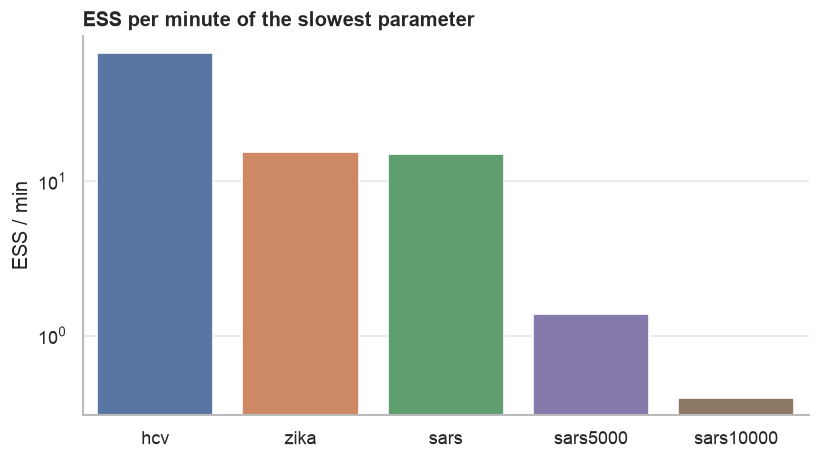

In [703]:
min_ess_per_minute_df = convergence_df.groupby("experiment", as_index=False)["ess_per_minute"].min()

fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(min_ess_per_minute_df, x="experiment", y="ess_per_minute", hue="experiment", order=experiments, palette=experiment_colors, ax=ax)
ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("ESS / min")
ax.set_title("ESS per minute of the slowest parameter")

fig.tight_layout()
plt.show()